In [87]:
#Set Up
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


In [88]:
# Import Movie Data
movie_data = pd.read_csv("archive/movies.csv", engine="python")  # untouched original

print(movie_data.shape)
print(movie_data.columns.tolist())

movie_data_copy = movie_data.copy()  # the copy we will clean

(9771, 22)
['id', 'title', 'original_title', 'overview', 'release_date', 'runtime', 'budget', 'revenue', 'vote_average', 'vote_count', 'popularity', 'poster_path', 'backdrop_path', 'status', 'tagline', 'homepage', 'original_language', 'adult', 'video', 'created_at', 'updated_at', 'genres']


In [89]:
# Convert strings to numbers and dates
movie_data_copy["id"] = pd.to_numeric(movie_data_copy["id"], errors="coerce")
movie_data_copy["vote_average"] = pd.to_numeric(movie_data_copy["vote_average"], errors="coerce")
movie_data_copy["vote_count"] = pd.to_numeric(movie_data_copy["vote_count"], errors="coerce")
movie_data_copy["release_date"] = pd.to_datetime(movie_data_copy["release_date"], errors="coerce")

# Release year (needed for the inflation adjustment later)
movie_data_copy["year"] = movie_data_copy["release_date"].dt.year

# TMDb uses 0 to mean "unknown", so convert it to NaN
movie_data_copy[["budget", "revenue"]] = movie_data_copy[["budget", "revenue"]].replace(0, np.nan)

In [90]:
na = movie_data_copy.isna().sum().to_frame("na_count")
na["na_pct"] = (na["na_count"] / len(movie_data_copy) * 100).round(1)
print(na.sort_values("na_pct", ascending=False).head(10))

data_clean = movie_data_copy.dropna(subset=["budget", "revenue", "year"]).copy()
data_clean["year"] = data_clean["year"].astype(int)
print(f"Kept {len(data_clean)} of {len(movie_data_copy)} ({len(data_clean)/len(movie_data_copy):.1%})")

               na_count  na_pct
homepage           6337    64.9
budget             5756    58.9
revenue            5744    58.8
tagline            3803    38.9
backdrop_path      1519    15.5
poster_path         338     3.5
genres              270     2.8
overview            160     1.6
release_date         62     0.6
year                 62     0.6
Kept 3434 of 9771 (35.1%)


In [91]:
##Inspect data for placeholders
print(data_clean.nsmallest(20, "budget")[["title", "year", "budget", "revenue"]])
print(data_clean.nsmallest(20, "revenue")[["title", "year", "budget", "revenue"]])

##Remove placeholders
MIN_VALUE = 10_000   # change this after reading Cell 5's output

before = len(data_clean)
data_clean = data_clean[
    (data_clean["budget"] >= MIN_VALUE) & (data_clean["revenue"] >= MIN_VALUE)
].copy()
print(f"Dropped {before - len(data_clean)} rows with budget or revenue under ${MIN_VALUE:,}")
print(f"{len(data_clean)} rows remain")

                    title  year   budget      revenue
8432               Anatar  2023      1.0       3608.0
4930        HalloweeNight  2009      4.0          1.0
2629             Hellbent  2005     85.0     183066.0
2611           Quiet City  2007   2500.0      15425.0
1371            Following  1999   6000.0      48482.0
6732             Katyusha  2018  10000.0     100000.0
3553              Captive  2012  11180.0      24591.0
285        Pink Flamingos  1972  12000.0    6000000.0
1903  Paranormal Activity  2007  15000.0  193355800.0
8266          Skinamarink  2023  15000.0    2131183.0
2003             Zero Day  2003  20000.0       8466.0
1541              Slacker  1991  23000.0    1228108.0
588                Clerks  1994  27575.0    3151130.0
5836            Terrifier  2018  35000.0     421798.0
8295                 Niki  2024  42744.0    1157127.0
4323          Billionaire  1986  44350.0     194300.0
4326            Coherence  2014  50000.0     139745.0
4734              Özleyiş  1

In [92]:
##Adjust for inflation
cpi = pd.read_csv("CPIAUCSL.csv")
cpi.columns = ["date", "cpi"]
cpi["year"] = pd.to_datetime(cpi["date"]).dt.year
cpi_year = cpi.groupby("year")["cpi"].mean()

base_year = 2025
base_cpi = cpi_year.loc[base_year]

data_clean["adj_factor"] = base_cpi / data_clean["year"].map(cpi_year)
data_clean["budget_adj"] = data_clean["budget"] * data_clean["adj_factor"]
data_clean["revenue_adj"] = data_clean["revenue"] * data_clean["adj_factor"]

before = len(data_clean)
data_clean = data_clean.dropna(subset=["adj_factor"]).copy()
print(f"Dropped {before - len(data_clean)} films released before {cpi_year.index.min()} (no CPI data)")
print(f"{len(data_clean)} rows remain")

Dropped 32 films released before 1947 (no CPI data)
3376 rows remain


                n  median_roi
budget_tier                  
<$10M         518    2.635543
$10-50M      1280    2.619707
$50-150M     1095    2.540594
>$150M        483    2.789978


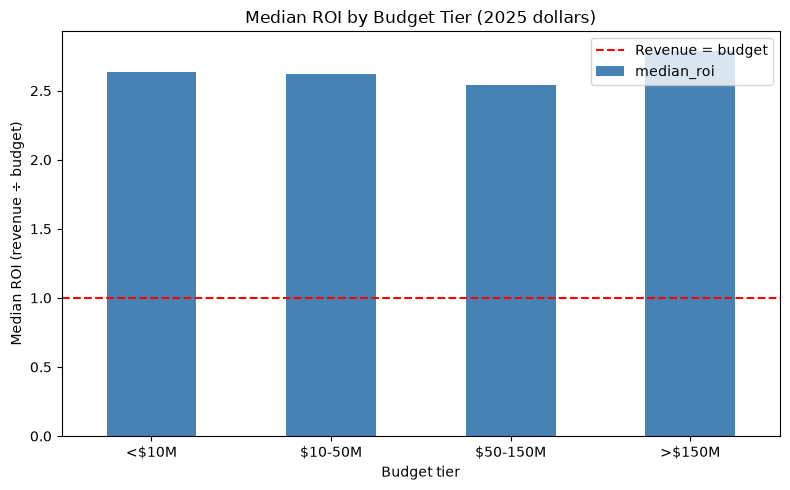

In [93]:
data_clean["roi"] = data_clean["revenue"] / data_clean["budget"]

data_clean["budget_tier"] = pd.cut(
    data_clean["budget_adj"],
    bins=[0, 10e6, 50e6, 150e6, float("inf")],
    labels=["<$10M", "$10-50M", "$50-150M", ">$150M"]
)

tier_summary = data_clean.groupby("budget_tier", observed=True).agg(
    n=("roi", "size"),
    median_roi=("roi", "median"),
)
print(tier_summary)

ax = tier_summary["median_roi"].plot(kind="bar", color="steelblue", figsize=(8, 5))
ax.axhline(1, color="red", linestyle="--", label="Revenue = budget")
ax.set_title("Median ROI by Budget Tier (2025 dollars)")
ax.set_xlabel("Budget tier")
ax.set_ylabel("Median ROI (revenue ÷ budget)")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

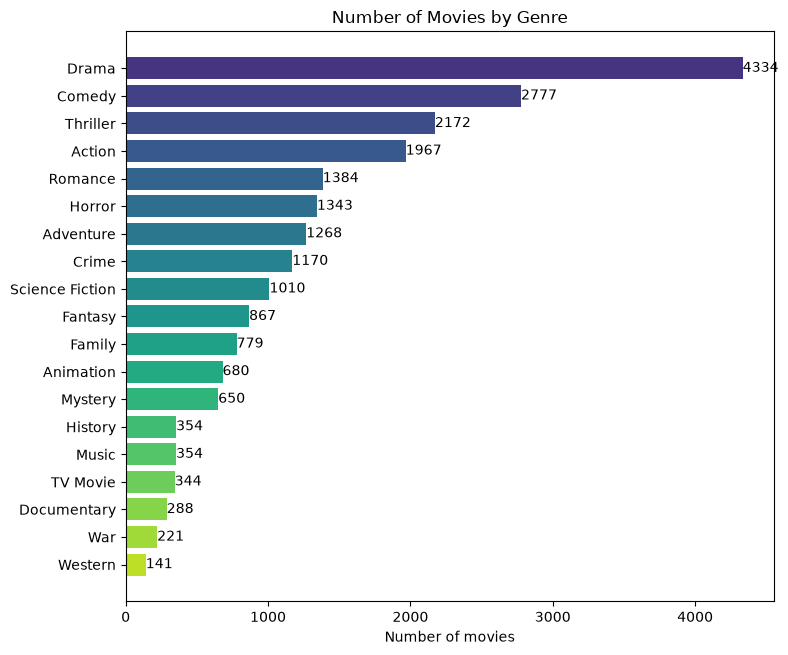

In [94]:
genres = pd.read_csv("archive/genres.csv", engine="python")

genres_sorted = genres.sort_values("movie_count", ascending=False)

n = len(genres_sorted)
colors = plt.cm.viridis(np.linspace(0.15, 0.9, n))

fig, ax = plt.subplots(figsize=(8, max(6, n * 0.35)))
bars = ax.barh(genres_sorted["name"], genres_sorted["movie_count"], color=colors)

ax.invert_yaxis()
ax.bar_label(bars)
ax.set_title("Number of Movies by Genre")
ax.set_xlabel("Number of movies")
plt.tight_layout()
plt.show()

log-log slope: 0.94


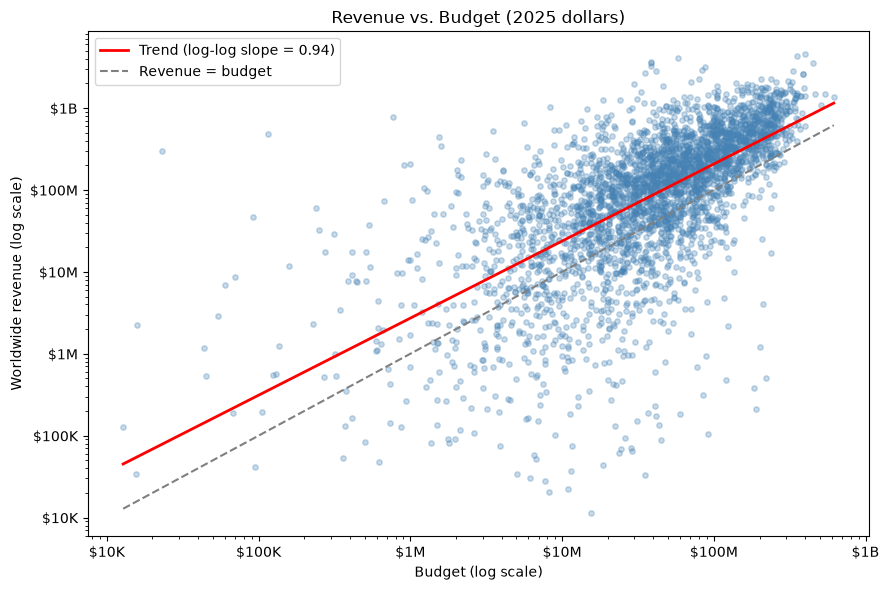

In [95]:
def dollars(x, pos):
    """Turn 1000000 into $1M. Matplotlib passes (value, tick position)."""
    if x >= 1e9:
        return f"${x/1e9:g}B"
    if x >= 1e6:
        return f"${x/1e6:g}M"
    if x >= 1e3:
        return f"${x/1e3:g}K"
    return f"${x:g}"

x = np.log10(data_clean["budget_adj"])
y = np.log10(data_clean["revenue_adj"])
slope, intercept = np.polyfit(x, y, 1)
print(f"log-log slope: {slope:.2f}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(data_clean["budget_adj"], data_clean["revenue_adj"],
           alpha=0.3, s=15, color="steelblue")

x_line = np.linspace(x.min(), x.max(), 100)
ax.plot(10**x_line, 10**(intercept + slope * x_line),
        color="red", linewidth=2, label=f"Trend (log-log slope = {slope:.2f})")
ax.plot(10**x_line, 10**x_line,
        color="gray", linestyle="--", label="Revenue = budget")

ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(dollars))
ax.yaxis.set_major_formatter(FuncFormatter(dollars))
ax.set_title("Revenue vs. Budget (2025 dollars)")
ax.set_xlabel("Budget (log scale)")
ax.set_ylabel("Worldwide revenue (log scale)")
ax.legend()
plt.tight_layout()
plt.show()

In [96]:
##Diagnose Errors

print("NaN in x:", x.isna().sum(), "| inf in x:", np.isinf(x).sum())
print("NaN in y:", y.isna().sum(), "| inf in y:", np.isinf(y).sum())
print(data_clean["year"].min(), data_clean["year"].max())
print(cpi_year.index.min(), cpi_year.index.max())

missing = data_clean[data_clean["adj_factor"].isna()]
print(len(missing))
print(missing["year"].min(), missing["year"].max())

NaN in x: 0 | inf in x: 0
NaN in y: 0 | inf in y: 0
1948 2026
1947 2026
0
nan nan


<Axes: >

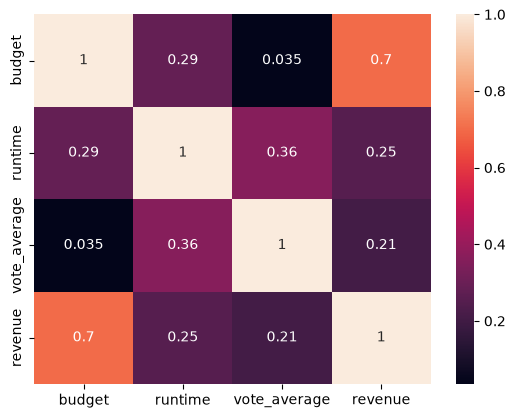

In [101]:
sns.heatmap(data_clean[["budget","runtime","vote_average","revenue"]].corr(),annot = True)


In [99]:
print(data_clean.columns)


Index(['id', 'title', 'original_title', 'overview', 'release_date', 'runtime',
       'budget', 'revenue', 'vote_average', 'vote_count', 'popularity',
       'poster_path', 'backdrop_path', 'status', 'tagline', 'homepage',
       'original_language', 'adult', 'video', 'created_at', 'updated_at',
       'genres', 'year', 'adj_factor', 'budget_adj', 'revenue_adj', 'roi',
       'budget_tier'],
      dtype='str')
